# Experiment: Skewness, Min-Max Scaling and Encoding

**Dataset:** `Sub_Division_IMD_2017(2).csv`  
**Records:** 4,188 subdivision-year observations  
**Purpose:** Explore skewness, normalize numerical rainfall attributes, demonstrate ordinal and one-hot encoding, and verify statistical properties.

> **Dataset note:** The CSV contains `SUBDIVISION` (nominal), `YEAR`, monthly rainfall, annual rainfall and seasonal rainfall aggregates. It does not contain a naturally ordinal categorical column. For the required ordinal-encoding demonstration, `YEAR_PERIOD` is derived transparently from `YEAR` as Early, Middle and Recent. `YEAR` is retained as a time identifier.

## 1. Import libraries and load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from IPython.display import display

sns.set_theme(style="whitegrid")
df = pd.read_csv("Sub_Division_IMD_2017(2).csv")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))
display(df.head())

Dataset shape: (4188, 19)

Column names: ['SUBDIVISION', 'YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JF', 'MAM', 'JJAS', 'OND']

Data types:
SUBDIVISION     object
YEAR             int64
JAN            float64
FEB            float64
MAR            float64
APR            float64
MAY            float64
JUN            float64
JUL            float64
AUG            float64
SEP            float64
OCT            float64
NOV            float64
DEC            float64
ANNUAL         float64
JF             float64
MAM            float64
JJAS           float64
OND            float64
dtype: object

Missing values:


,Missing values
SUBDIVISION,0
YEAR,0
JAN,4
FEB,3
MAR,6
APR,4
MAY,3
JUN,5
JUL,7
AUG,4


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


## 2. Separate features and handle missing values
Numeric missing values are filled with the column median; categorical missing values are filled with the mode. The original `df` is preserved for comparison.

In [2]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical features:", numeric_cols)
print("Categorical features:", categorical_cols)

data = df.copy()
for col in numeric_cols:
    data[col] = data[col].fillna(data[col].median())
for col in categorical_cols:
    data[col] = data[col].fillna(data[col].mode()[0])

print("\nMissing values after treatment:", int(data.isnull().sum().sum()))

Numerical features: ['YEAR', 'JAN', 'FEB', 'MAR', 'APR', 'MAY', 'JUN', 'JUL', 'AUG', 'SEP', 'OCT', 'NOV', 'DEC', 'ANNUAL', 'JF', 'MAM', 'JJAS', 'OND']
Categorical features: ['SUBDIVISION']

Missing values after treatment: 0


## 3. Study skewness using histograms and KDE
The following plots show the distributions of January, July and annual rainfall. Skewness values are printed below the plots.

Skewness:


,Skewness
JAN,4.316503
JUL,2.102420
ANNUAL,1.326679


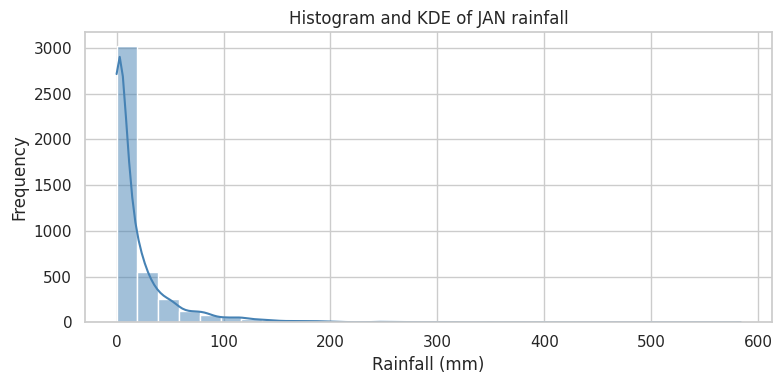

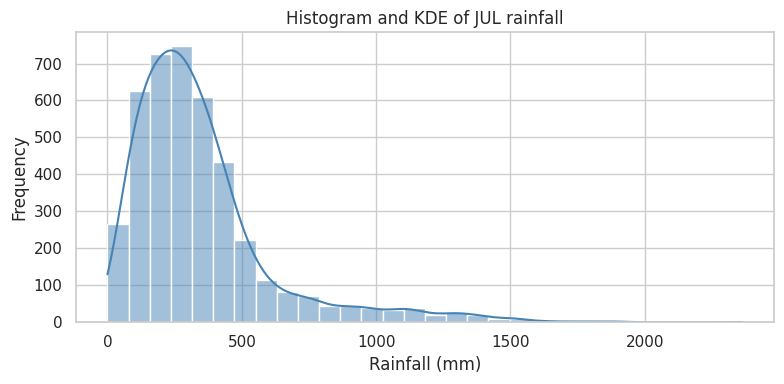

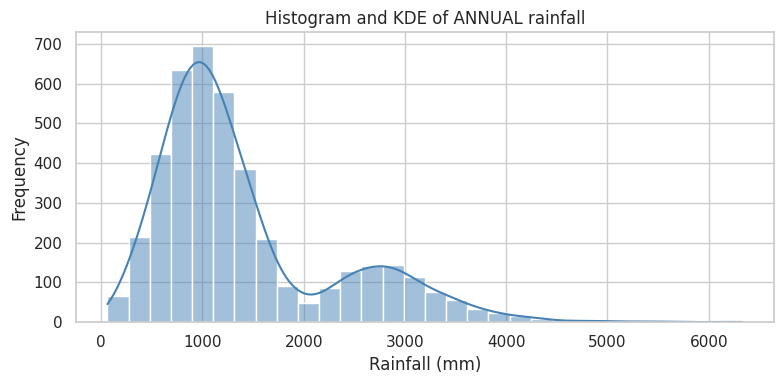

In [3]:
selected_features = ["JAN", "JUL", "ANNUAL"]
skewness_values = data[selected_features].skew()
print("Skewness:")
display(skewness_values.to_frame("Skewness"))

for col in selected_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(data[col], kde=True, bins=30, color="steelblue")
    plt.title(f"Histogram and KDE of {col} rainfall")
    plt.xlabel("Rainfall (mm)")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

## 4. Manual Min-Max scaling and Scikit-Learn MinMaxScaler

Manual formula:

\[
X_{scaled} = \frac{X - X_{min}}{X_{max} - X_{min}}
\]

`YEAR` is excluded because it is a time identifier, not a rainfall measurement.

In [4]:
scale_cols = [col for col in numeric_cols if col != "YEAR"]

# Manual Min-Max scaling
manual_scaled = data[scale_cols].copy()
for col in scale_cols:
    xmin = data[col].min()
    xmax = data[col].max()
    if xmax == xmin:
        manual_scaled[col] = 0.0
    else:
        manual_scaled[col] = (data[col] - xmin) / (xmax - xmin)

# Scikit-Learn MinMaxScaler
minmax_scaler = MinMaxScaler()
sklearn_scaled = pd.DataFrame(
    minmax_scaler.fit_transform(data[scale_cols]),
    columns=scale_cols,
    index=data.index
)

print("Manual scaling — first five rows:")
display(manual_scaled.head())
print("Scikit-Learn scaling — first five rows:")
display(sklearn_scaled.head())

max_difference = np.abs(manual_scaled.to_numpy() - sklearn_scaled.to_numpy()).max()
print("Maximum absolute difference between the two methods:", max_difference)

Manual scaling — first five rows:


,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,0.084290,0.215861,0.048217,0.003865,0.452507,0.321280,0.154520,0.289018,0.272117,0.409680,0.860225,0.054413,0.528155,0.194853,0.320942,0.365867,0.782675
1,0.000000,0.396035,0.020145,0.000000,0.381739,0.333458,0.096877,0.452781,0.545135,0.207951,0.553244,0.259919,0.551685,0.228449,0.262516,0.475165,0.572216
2,0.021758,0.356877,0.000000,0.001680,0.201181,0.297919,0.308278,0.196263,0.277355,0.191079,0.438280,0.364372,0.461827,0.224017,0.135239,0.405536,0.551377
3,0.016104,0.036431,0.000000,0.340111,0.260568,0.307363,0.212460,0.096179,0.671332,0.234314,0.475728,0.064939,0.481320,0.034453,0.290354,0.428664,0.455888
4,0.002227,0.000000,0.005449,0.045202,0.239175,0.390370,0.156044,0.198546,0.242982,0.274913,0.039143,0.558219,0.399502,0.001858,0.177397,0.349927,0.503633


Scikit-Learn scaling — first five rows:


,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,0.084290,0.215861,0.048217,0.003865,0.452507,0.321280,0.154520,0.289018,0.272117,0.409680,0.860225,0.054413,0.528155,0.194853,0.320942,0.365867,0.782675
1,0.000000,0.396035,0.020145,0.000000,0.381739,0.333458,0.096877,0.452781,0.545135,0.207951,0.553244,0.259919,0.551685,0.228449,0.262516,0.475165,0.572216
2,0.021758,0.356877,0.000000,0.001680,0.201181,0.297919,0.308278,0.196263,0.277355,0.191079,0.438280,0.364372,0.461827,0.224017,0.135239,0.405536,0.551377
3,0.016104,0.036431,0.000000,0.340111,0.260568,0.307363,0.212460,0.096179,0.671332,0.234314,0.475728,0.064939,0.481320,0.034453,0.290354,0.428664,0.455888
4,0.002227,0.000000,0.005449,0.045202,0.239175,0.390370,0.156044,0.198546,0.242982,0.274913,0.039143,0.558219,0.399502,0.001858,0.177397,0.349927,0.503633


Maximum absolute difference between the two methods: 1.1102230246251565e-16


## 5. Ordinal encoding
The source dataset has no ordinal category. We derive `YEAR_PERIOD` from the year and encode the chronological order Early = 0, Middle = 1, Recent = 2.

In [5]:
data["YEAR_PERIOD"] = pd.cut(
    data["YEAR"],
    bins=[1900, 1940, 1980, 2020],
    labels=["Early", "Middle", "Recent"],
    include_lowest=True
)
ordinal_mapping = {"Early": 0, "Middle": 1, "Recent": 2}
data["YEAR_PERIOD_ENCODED"] = data["YEAR_PERIOD"].map(ordinal_mapping).astype(int)

print("Ordinal mapping:", ordinal_mapping)
display(data[["YEAR", "YEAR_PERIOD", "YEAR_PERIOD_ENCODED"]].head(10))
print("\nEncoded category counts:")
display(data["YEAR_PERIOD"].value_counts().sort_index().to_frame("Count"))

Ordinal mapping: {'Early': 0, 'Middle': 1, 'Recent': 2}


,YEAR,YEAR_PERIOD,YEAR_PERIOD_ENCODED
0,1901,Early,0
1,1902,Early,0
2,1903,Early,0
3,1904,Early,0
4,1905,Early,0
5,1906,Early,0
6,1907,Early,0
7,1908,Early,0
8,1910,Early,0
9,1911,Early,0



Encoded category counts:


,Count
YEAR_PERIOD,
Early,1423
Middle,1433
Recent,1332


## 6. One-Hot Encoding of nominal feature `SUBDIVISION`

`drop_first=True` omits one reference subdivision column. This avoids a redundant dummy column when the encoded features are used in a linear model with an intercept.

In [6]:
one_hot = pd.get_dummies(
    data["SUBDIVISION"],
    prefix="SUBDIVISION",
    drop_first=True,
    dtype=int
)

print("Original number of subdivision categories:", data["SUBDIVISION"].nunique())
print("Number of one-hot columns after drop_first=True:", one_hot.shape[1])
display(one_hot.head())

Original number of subdivision categories: 36
Number of one-hot columns after drop_first=True: 35


,SUBDIVISION_Arunachal Pradesh,SUBDIVISION_Assam & Meghalaya,SUBDIVISION_Bihar,SUBDIVISION_Chhattisgarh,SUBDIVISION_Coastal Andhra Pradesh,SUBDIVISION_Coastal Karnataka,SUBDIVISION_East Madhya Pradesh,SUBDIVISION_East Rajasthan,SUBDIVISION_East Uttar Pradesh,SUBDIVISION_Gangetic West Bengal,SUBDIVISION_Gujarat Region,SUBDIVISION_Haryana Delhi & Chandigarh,SUBDIVISION_Himachal Pradesh,SUBDIVISION_Jammu & Kashmir,SUBDIVISION_Jharkhand,SUBDIVISION_Kerala,SUBDIVISION_Konkan & Goa,SUBDIVISION_Lakshadweep,SUBDIVISION_Madhya Maharashtra,SUBDIVISION_Matathwada,SUBDIVISION_Naga Mani Mizo Tripura,SUBDIVISION_North Interior Karnataka,SUBDIVISION_Orissa,SUBDIVISION_Punjab,SUBDIVISION_Rayalseema,SUBDIVISION_Saurashtra & Kutch,SUBDIVISION_South Interior Karnataka,SUBDIVISION_Sub Himalayan West Bengal & Sikkim,SUBDIVISION_Tamil Nadu,SUBDIVISION_Telangana,SUBDIVISION_Uttarakhand,SUBDIVISION_Vidarbha,SUBDIVISION_West Madhya Pradesh,SUBDIVISION_West Rajasthan,SUBDIVISION_West Uttar Pradesh
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 7. Compare original and transformed datasets

In [7]:
transformed = pd.concat(
    [
        data[["YEAR"]].reset_index(drop=True),
        manual_scaled.add_suffix("_MINMAX").reset_index(drop=True),
        data[["YEAR_PERIOD_ENCODED"]].reset_index(drop=True),
        one_hot.reset_index(drop=True)
    ],
    axis=1
)

print("Original dataset — first five rows:")
display(df.head())
print("Transformed dataset — first five rows:")
display(transformed.head())

print("Original shape:", df.shape)
print("Transformed shape:", transformed.shape)

Original dataset — first five rows:


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,JF,MAM,JJAS,OND
0,Andaman & Nicobar Islands,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,Andaman & Nicobar Islands,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,Andaman & Nicobar Islands,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6
3,Andaman & Nicobar Islands,1904,9.4,14.7,0.0,202.4,304.5,495.1,502.0,160.1,820.4,222.2,308.7,40.1,3079.6,24.1,506.9,1977.6,571.0
4,Andaman & Nicobar Islands,1905,1.3,0.0,3.3,26.9,279.5,628.7,368.7,330.5,297.0,260.7,25.4,344.7,2566.7,1.3,309.7,1624.9,630.8


Transformed dataset — first five rows:


,YEAR,JAN_MINMAX,FEB_MINMAX,MAR_MINMAX,APR_MINMAX,MAY_MINMAX,JUN_MINMAX,JUL_MINMAX,AUG_MINMAX,SEP_MINMAX,OCT_MINMAX,NOV_MINMAX,DEC_MINMAX,ANNUAL_MINMAX,JF_MINMAX,MAM_MINMAX,JJAS_MINMAX,OND_MINMAX,YEAR_PERIOD_ENCODED,SUBDIVISION_Arunachal Pradesh,SUBDIVISION_Assam & Meghalaya,SUBDIVISION_Bihar,SUBDIVISION_Chhattisgarh,SUBDIVISION_Coastal Andhra Pradesh,SUBDIVISION_Coastal Karnataka,SUBDIVISION_East Madhya Pradesh,SUBDIVISION_East Rajasthan,SUBDIVISION_East Uttar Pradesh,SUBDIVISION_Gangetic West Bengal,SUBDIVISION_Gujarat Region,SUBDIVISION_Haryana Delhi & Chandigarh,SUBDIVISION_Himachal Pradesh,SUBDIVISION_Jammu & Kashmir,SUBDIVISION_Jharkhand,SUBDIVISION_Kerala,SUBDIVISION_Konkan & Goa,SUBDIVISION_Lakshadweep,SUBDIVISION_Madhya Maharashtra,SUBDIVISION_Matathwada,SUBDIVISION_Naga Mani Mizo Tripura,SUBDIVISION_North Interior Karnataka,SUBDIVISION_Orissa,SUBDIVISION_Punjab,SUBDIVISION_Rayalseema,SUBDIVISION_Saurashtra & Kutch,SUBDIVISION_South Interior Karnataka,SUBDIVISION_Sub Himalayan West Bengal & Sikkim,SUBDIVISION_Tamil Nadu,SUBDIVISION_Telangana,SUBDIVISION_Uttarakhand,SUBDIVISION_Vidarbha,SUBDIVISION_West Madhya Pradesh,SUBDIVISION_West Rajasthan,SUBDIVISION_West Uttar Pradesh
0,1901,0.084290,0.215861,0.048217,0.003865,0.452507,0.321280,0.154520,0.289018,0.272117,0.409680,0.860225,0.054413,0.528155,0.194853,0.320942,0.365867,0.782675,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1902,0.000000,0.396035,0.020145,0.000000,0.381739,0.333458,0.096877,0.452781,0.545135,0.207951,0.553244,0.259919,0.551685,0.228449,0.262516,0.475165,0.572216,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1903,0.021758,0.356877,0.000000,0.001680,0.201181,0.297919,0.308278,0.196263,0.277355,0.191079,0.438280,0.364372,0.461827,0.224017,0.135239,0.405536,0.551377,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,1904,0.016104,0.036431,0.000000,0.340111,0.260568,0.307363,0.212460,0.096179,0.671332,0.234314,0.475728,0.064939,0.481320,0.034453,0.290354,0.428664,0.455888,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1905,0.002227,0.000000,0.005449,0.045202,0.239175,0.390370,0.156044,0.198546,0.242982,0.274913,0.039143,0.558219,0.399502,0.001858,0.177397,0.349927,0.503633,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


Original shape: (4188, 19)
Transformed shape: (4188, 54)


## 8. Verify normalized and standardized statistical properties
Min-Max features should have minimum 0 and maximum 1. Standardized features should have mean approximately 0 and population standard deviation approximately 1. Standardization is a separate operation from Min-Max normalization.

In [8]:
minmax_verification = pd.DataFrame({
    "Minimum": sklearn_scaled.min(),
    "Maximum": sklearn_scaled.max()
})
print("Min-Max verification (expected minimum=0, maximum=1):")
display(minmax_verification.round(6))

standardized_array = StandardScaler().fit_transform(data[scale_cols])
standardized = pd.DataFrame(standardized_array, columns=scale_cols)
standard_verification = pd.DataFrame({
    "Mean": standardized.mean(),
    "Population standard deviation": standardized.std(ddof=0)
})
print("Standardization verification (expected mean≈0, population std≈1):")
display(standard_verification.round(6))

print("Maximum absolute mean after standardization:",
      standardized.mean().abs().max())
print("Maximum absolute difference of population std from 1:",
      (standardized.std(ddof=0) - 1).abs().max())

Min-Max verification (expected minimum=0, maximum=1):


,Minimum,Maximum
JAN,0.0,1.0
FEB,0.0,1.0
MAR,0.0,1.0
APR,0.0,1.0
MAY,0.0,1.0
JUN,0.0,1.0
JUL,0.0,1.0
AUG,0.0,1.0
SEP,0.0,1.0
OCT,0.0,1.0


Standardization verification (expected mean≈0, population std≈1):


,Mean,Population standard deviation
JAN,-0.0,1.0
FEB,0.0,1.0
MAR,-0.0,1.0
APR,0.0,1.0
MAY,-0.0,1.0
JUN,-0.0,1.0
JUL,0.0,1.0
AUG,0.0,1.0
SEP,0.0,1.0
OCT,-0.0,1.0


Maximum absolute mean after standardization: 1.730548210303969e-16
Maximum absolute difference of population std from 1: 2.220446049250313e-16


## 9. Interpretation and conclusion

- A positive skewness value indicates a longer right tail; a negative value indicates a longer left tail.
- Histograms show the frequency distribution, while KDE provides a smoothed view of the distribution.
- Manual Min-Max scaling and Scikit-Learn `MinMaxScaler` should produce the same results (up to floating-point precision).
- Min-Max normalization maps each selected rainfall feature to the interval [0, 1].
- Standardization produces features with mean approximately 0 and population standard deviation approximately 1.
- `YEAR_PERIOD` demonstrates ordinal encoding using chronological order.
- `SUBDIVISION` is nominal, so one-hot encoding is appropriate. `drop_first=True` removes one reference category to avoid redundant dummy variables.

**Conclusion:** The rainfall dataset was inspected and preprocessed using statistical visualization, Min-Max normalization, ordinal encoding and one-hot encoding. The scaling methods were compared and their expected statistical properties were verified. These preprocessing steps make heterogeneous numerical and categorical attributes more suitable for subsequent statistical analysis and machine-learning workflows.